In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


# Research summary · SAP RPT context and semantics

## Does Semantic Context Improve SAP-RPT Predictions?
Across three paired 512-row contexts, enhanced names and labels lowered late-payment F1 by about 0.022; fraud F1 stayed at zero. S4 and S5 are identity controls because the source needs no documented value repair. Validation favored S3 for late payment, but that gain reversed on final holdout. A separate validation-selected class-balanced context had a much larger effect on fraud recall, while adding false alarms.

In [2]:
semantic=pd.read_csv(ROOT/'data/semantic_ablation/results.csv')
selection=pd.read_csv(ROOT/'data/context_benchmark/selection_holdout_results.csv')
validation=pd.read_csv(ROOT/'data/context_benchmark/selection_validation_results.csv')
paired=semantic[semantic.model=='SAP-RPT'].pivot_table(index=['seed','target'],columns='condition',values='f1')
display((paired[['S1','S2','S3','S4','S5']].sub(paired['S0'],axis=0)).round(3))
display(selection.groupby(['target','strategy'])[['f1','recall','false_positives']].mean().round(3))

condition          S1     S2     S3   S4     S5
seed target                                    
11   is_fraud   0.000  0.000  0.000  0.0  0.000
     paid_late -0.030 -0.006 -0.014  0.0 -0.014
23   is_fraud   0.000  0.000  0.000  0.0  0.000
     paid_late -0.028 -0.028 -0.025  0.0 -0.025
37   is_fraud   0.000  0.000  0.000  0.0  0.000
     paid_late -0.014 -0.027 -0.027  0.0 -0.027

f1  recall  false_positives
target    strategy                                  
is_fraud  balanced    0.388   0.750             17.0
          diversity   0.000   0.000              0.2
          hybrid      0.000   0.000              1.0
          random      0.000   0.000              0.0
          similarity  0.000   0.000              1.0
          stratified  0.000   0.000              0.4
paid_late balanced    0.558   0.616             30.0
          diversity   0.514   0.529             23.0
          hybrid      0.630   0.784             36.0
          random      0.544   0.557             24.6
          similarity  0.579   0.608             25.0
          stratified  0.494   0.478             23.2

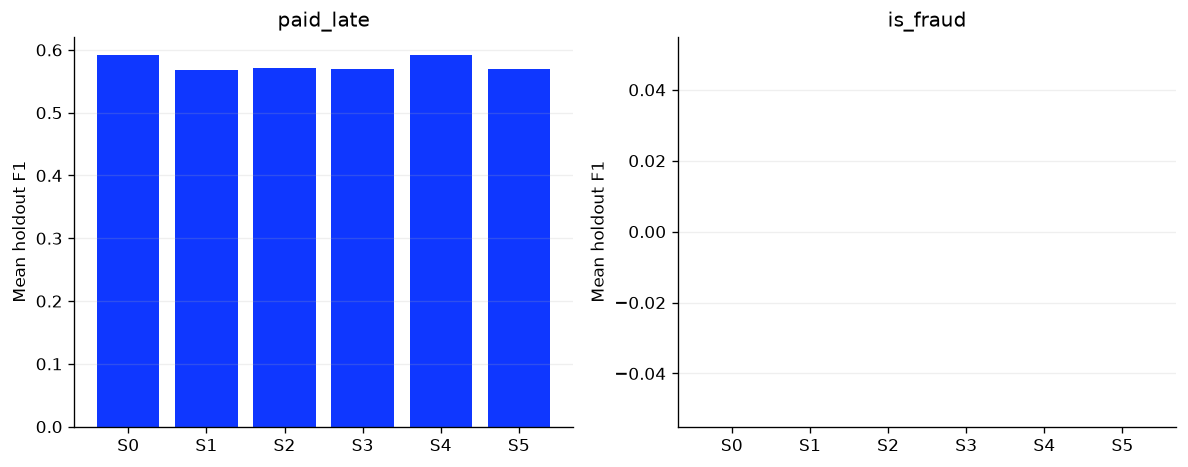

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,target in zip(axes,['paid_late','is_fraud']):
    sub=semantic[(semantic.model=='SAP-RPT')&(semantic.target==target)].groupby('condition').f1.mean()
    ax.bar(sub.index,sub,color='#0F37FF'); ax.set_title(target); ax.set_ylabel('Mean holdout F1'); ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()

## Interpretation
The original names are already descriptive and no text features exist. S4 and S5 are identity controls because there are no documented data-quality defects to repair. The semantic comparisons use three paired contexts, so interpret their differences as exploratory. Context selection is a separate intervention; use the validation-selected strategy only for final claims. See the Markdown report for exact results and limitations.